# DSCI 552 - Homework 6

**Name:** Chen Zhu | **GitHub:** ChenZhu50 | **USC ID:** 2370790492

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
# imblearn's Pipeline, so SMOTE can be a step
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

data_path = '../data'

## 1(a) Load data

In [2]:
# both files start with 20 lines of license text; missing values are written as 'na'
train = pd.read_csv(data_path + '/aps_failure_training_set.csv',
                    skiprows=20, na_values='na')
test = pd.read_csv(data_path + '/aps_failure_test_set.csv',
                   skiprows=20, na_values='na')
print(train.shape, test.shape)
train.head()

(60000, 171) (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## 1(b) Data preparation

In [3]:
X_train_raw, y_train = train.drop(
    columns='class'), (train['class'] == 'pos').astype(int)
X_test_raw, y_test = test.drop(
    columns='class'), (test['class'] == 'pos').astype(int)

missing = X_train_raw.isna().mean().sort_values(ascending=False)
print('features with missing values:',
      (missing > 0).sum(), 'of', X_train_raw.shape[1])
print('rows with at least one missing value: %.2f%%' %
      (100 * X_train_raw.isna().any(axis=1).mean()))
print('missing cells: %.2f%%' % (100 * X_train_raw.isna().mean().mean()))
missing.head(10)

features with missing values: 169 of 170
rows with at least one missing value: 99.02%
missing cells: 8.33%


br_000    0.821067
bq_000    0.812033
bp_000    0.795667
bo_000    0.772217
cr_000    0.772150
ab_000    0.772150
bn_000    0.733483
bm_000    0.659150
bl_000    0.454617
bk_000    0.383900
dtype: float64

### 1(b)i. Missing values

Common methods include deletion, mean/median/mode imputation, KNN, and iterative regression (MICE). Deletion would remove 99% of training rows here. I use medians because the features are skewed and this method is fast. Following footnote 1, training and test data use their own medians. All 170 features are kept; during CV, medians are fitted on the training folds only.

In [4]:
# median imputation; the test set is filled with its own medians (footnote 1)
X_train = X_train_raw.fillna(X_train_raw.median())
X_test = X_test_raw.fillna(X_test_raw.median())
print('missing after imputation:',
      X_train.isna().sum().sum(), X_test.isna().sum().sum())

missing after imputation: 0 0


### 1(b)ii. Coefficient of Variation

In [5]:
cv_feat = (X_train.std() / X_train.mean()).sort_values(ascending=False)
print('constant features (CV = 0):', list(cv_feat.index[cv_feat == 0]))
print('max value of cf_000, co_000, ad_000:',
      X_train[['cf_000', 'co_000', 'ad_000']].max().tolist())
print()
# CV of all 170 features, sorted
print(textwrap.fill(
    ', '.join(f'{k}: {v:.2f}' for k, v in cv_feat.items()), 79))

constant features (CV = 0): ['cd_000']
max value of cf_000, co_000, ad_000: [8584297736.0, 8584297742.0, 8584297742.0]

cf_000: 244.89, co_000: 244.51, ad_000: 244.32, cs_009: 237.93, dh_000: 123.22,
dj_000: 117.49, ag_000: 92.92, as_000: 87.33, ay_009: 84.73, ak_000: 80.42,
az_009: 77.84, ch_000: 77.45, au_000: 68.88, cr_000: 58.08, ay_001: 52.82,
df_000: 52.29, dz_000: 51.33, ef_000: 49.37, cs_008: 48.10, aj_000: 44.27,
eg_000: 42.48, dl_000: 39.74, ay_002: 39.25, dg_000: 38.49, ay_000: 37.43,
dk_000: 37.04, cy_000: 36.60, dm_000: 36.26, ag_001: 35.25, ea_000: 34.95,
cn_009: 34.27, ay_004: 33.75, ag_009: 33.36, da_000: 29.37, ay_003: 28.74,
cn_000: 26.34, ae_000: 24.20, at_000: 23.71, az_008: 22.68, dq_000: 22.03,
af_000: 19.47, ai_000: 18.20, ag_002: 17.57, az_007: 16.23, cl_000: 14.97,
cz_000: 14.51, cp_000: 13.93, az_002: 13.27, ay_005: 12.52, di_000: 11.83,
ar_000: 11.35, cn_001: 11.26, cj_000: 11.07, ab_000: 10.38, cn_008: 9.73,
ba_009: 9.43, az_000: 9.41, al_000: 9.17, am_0: 9.

Most features have large CVs: the median is 4.9, and 159 of 170 exceed 1. The top three contain extreme values around 8.58e9, giving CVs near 245. The constant feature cd_000 has CV = 0.

### 1(b)iii. Correlation matrix

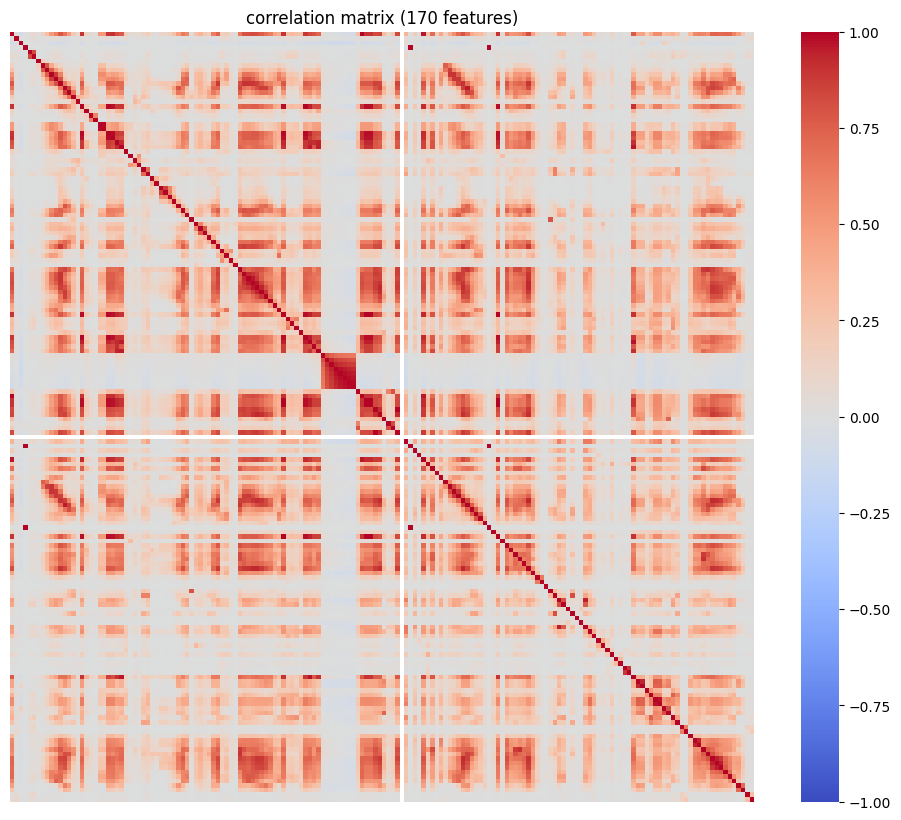

feature pairs with |r| > 0.9: 130 of 14196
feature pairs with |r| > 0.5: 1784


In [6]:
# cd_000 is constant, so its row / column is NaN (blank line in the plot)
corr = X_train.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1,
            vmax=1, xticklabels=False, yticklabels=False)
plt.title('correlation matrix (170 features)')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('feature pairs with |r| > 0.9:',
      (pairs.abs() > 0.9).sum(), 'of', len(pairs))
print('feature pairs with |r| > 0.5:', (pairs.abs() > 0.5).sum())

Many features are correlated: 1784 pairs have |r| > 0.5 and 130 have |r| > 0.9. Several counters carry similar information. The blank row and column are cd_000, which is constant.

### 1(b)iv. Top ⌊√170⌋ = 13 features by CV

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


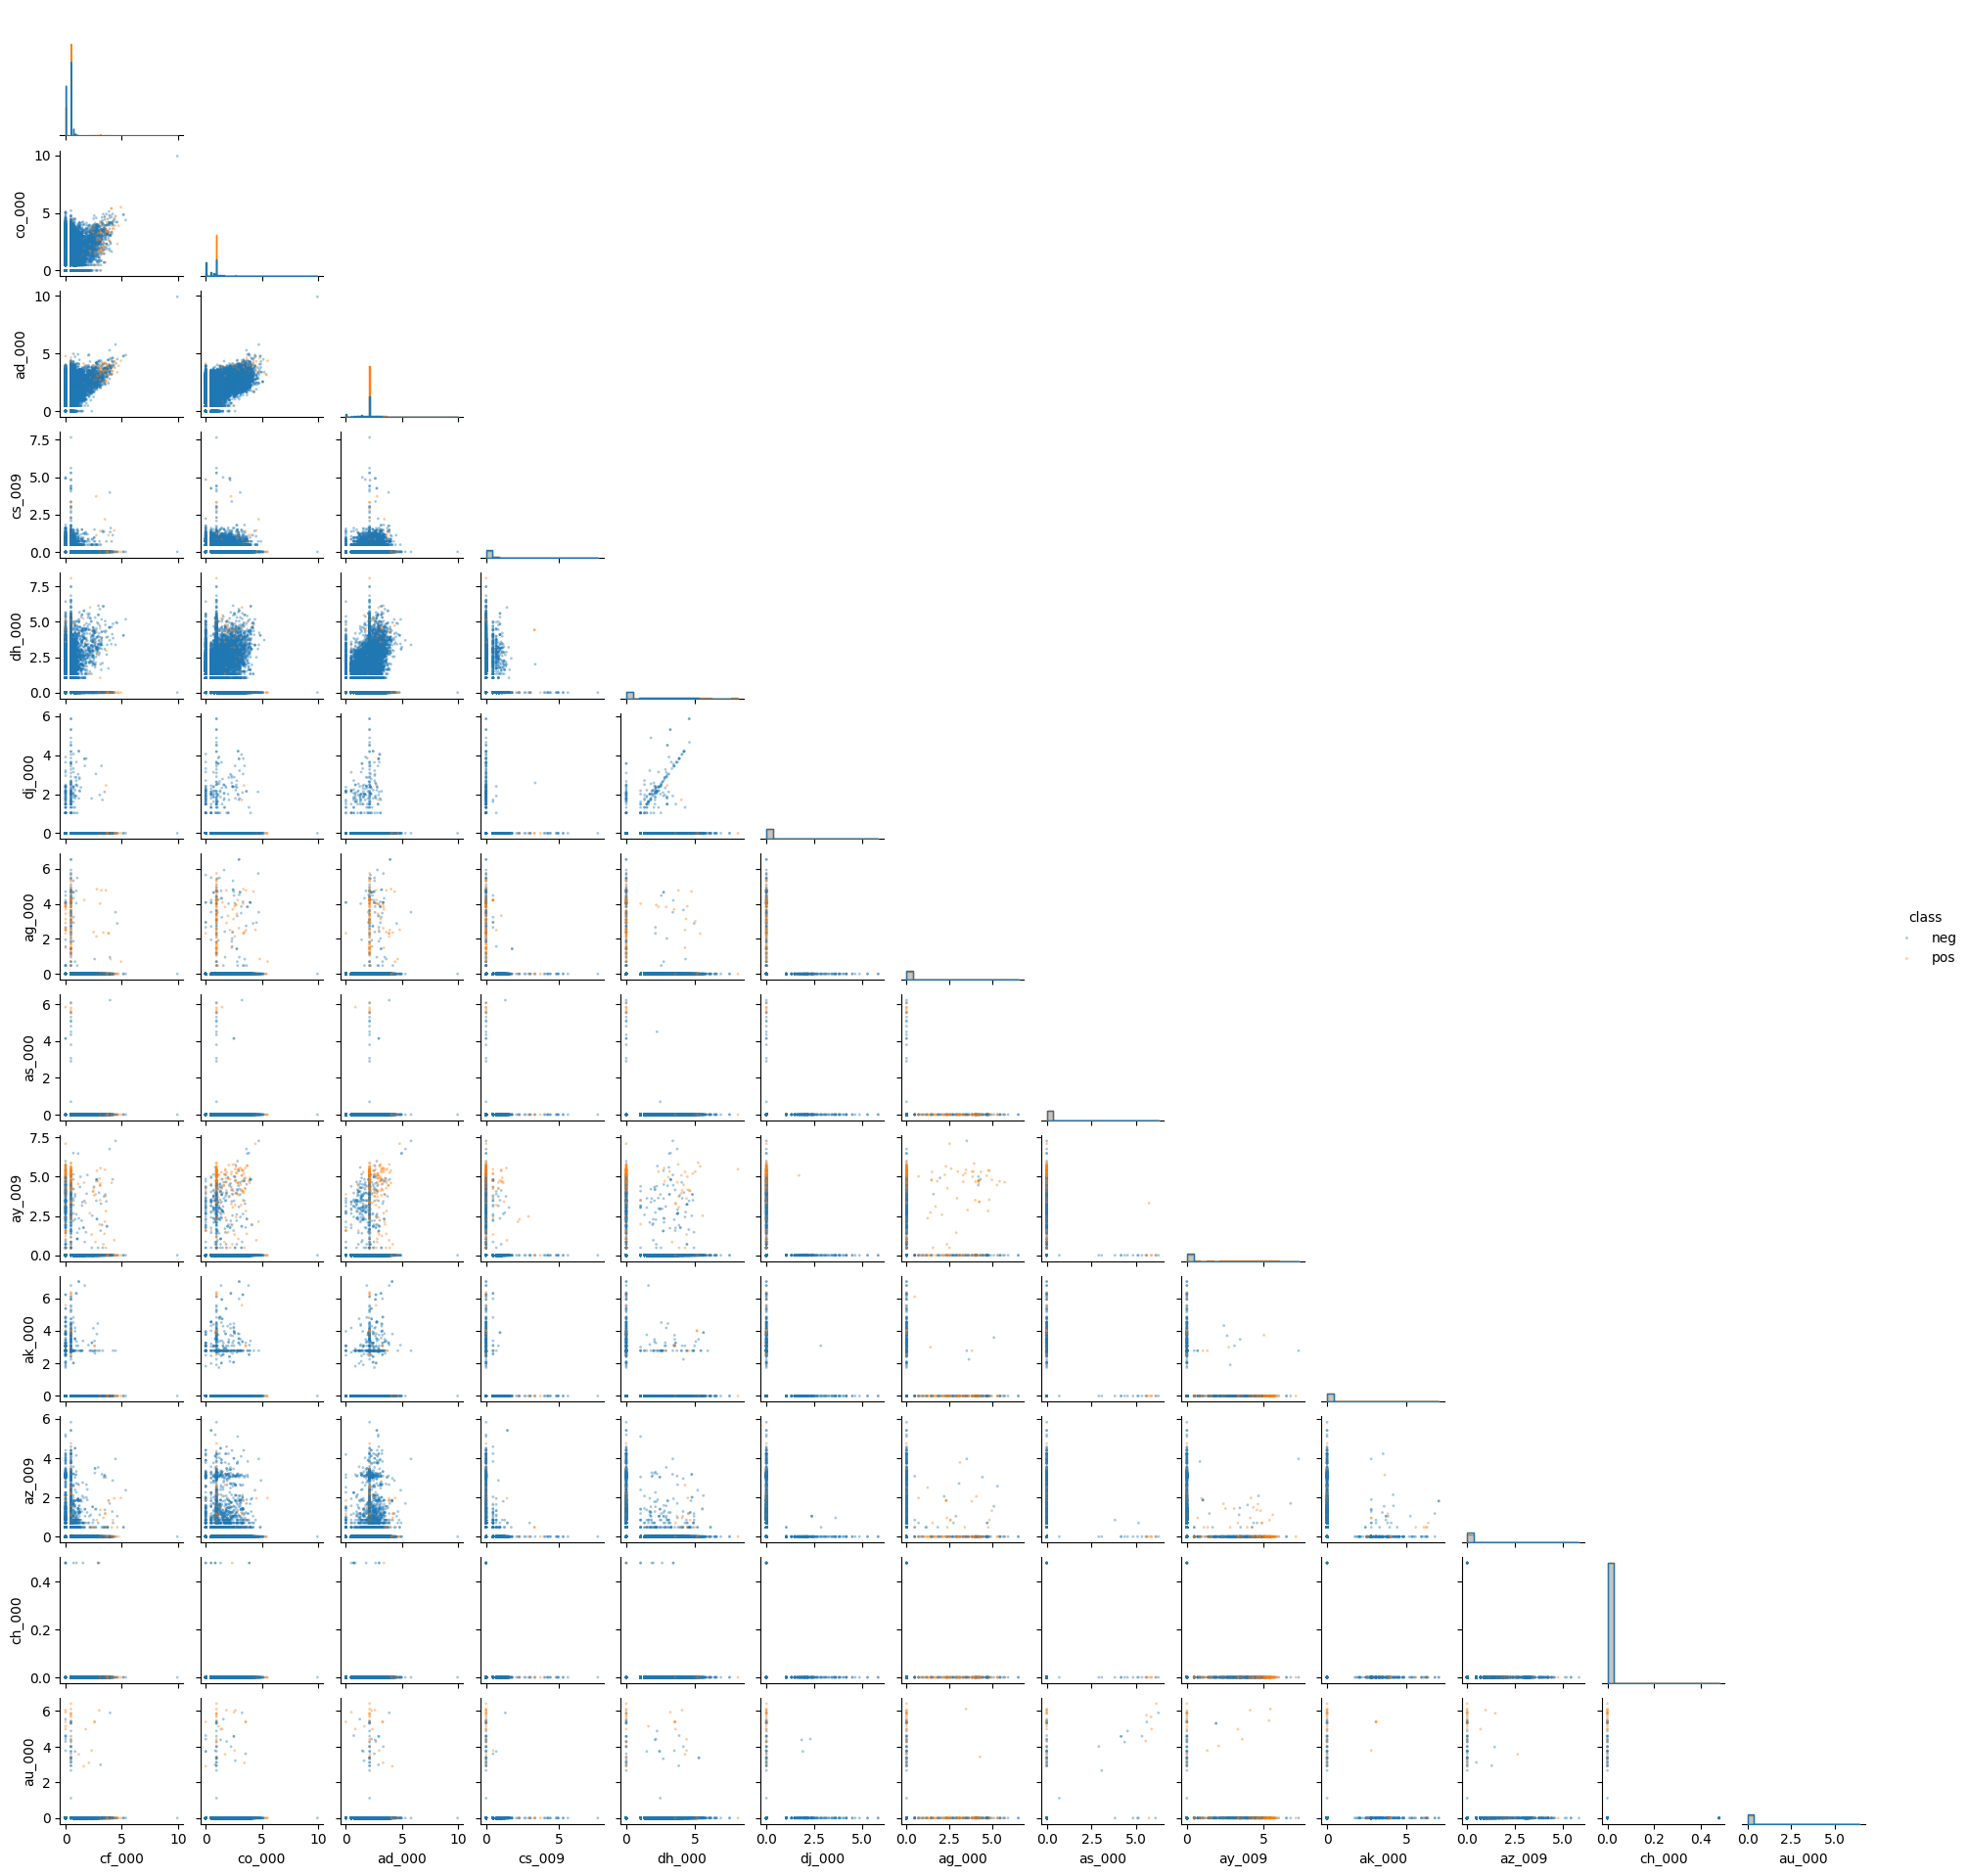

In [7]:
top = cv_feat.index[:int(np.sqrt(170))]
print(list(top))

# values go from 0 up to 8.6e9 and most of them are 0, so the plots use log10(1 + x);
# on the raw scale almost every point sits on top of each other at 0
plot_df = np.log10(1 + X_train[top])
plot_df['class'] = train['class']

# scatter plots like ISLR Fig. 4.1 (left), pos drawn on top of neg
sns.pairplot(plot_df, hue='class', hue_order=['neg', 'pos'], corner=True, height=1.5,
             plot_kws={'s': 4, 'alpha': 0.4, 'linewidth': 0},
             diag_kind='hist', diag_kws={'stat': 'density', 'common_norm': False, 'element': 'step'})
plt.show()

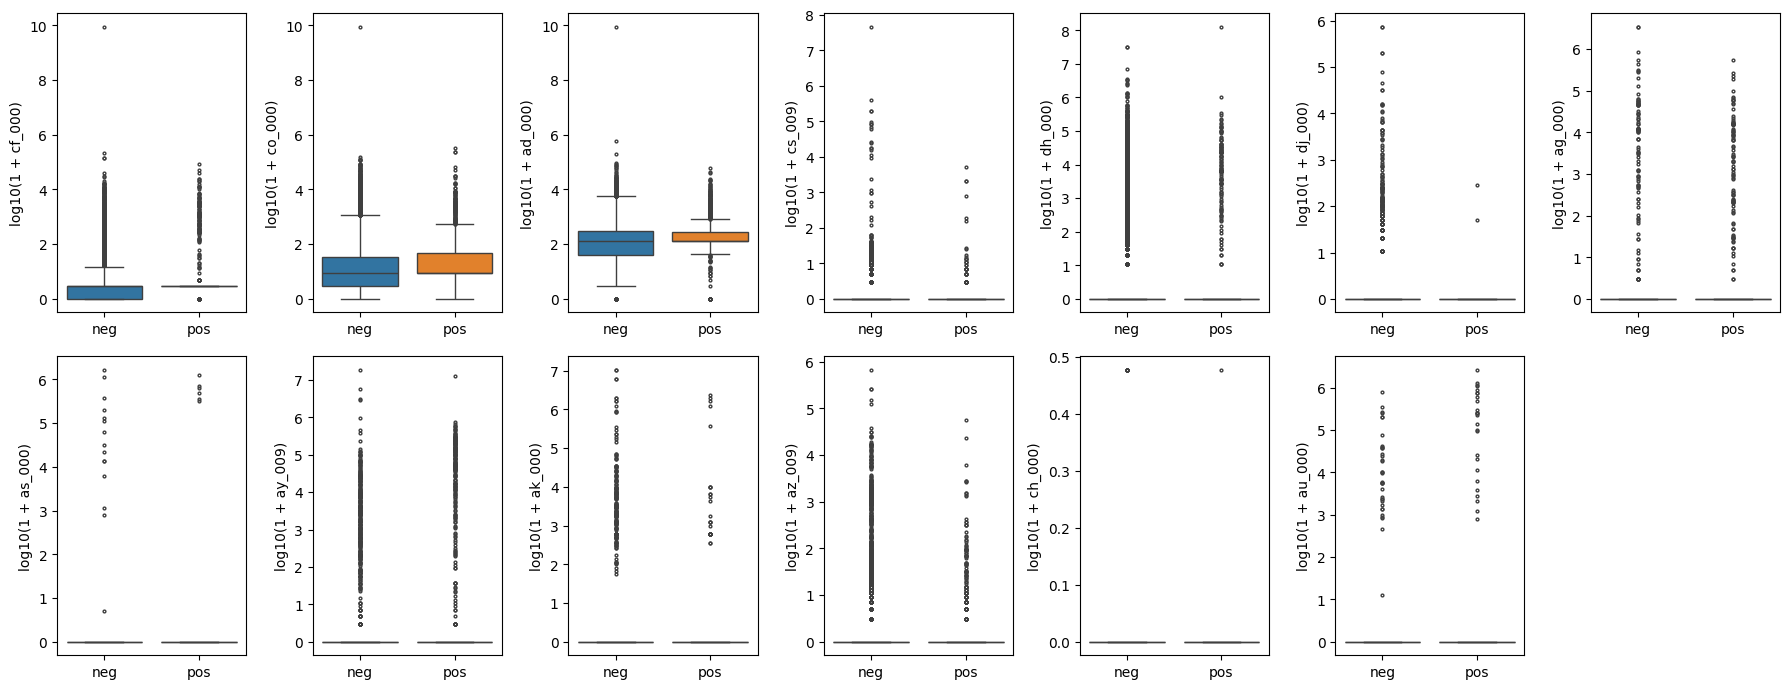

,nonzero neg,nonzero pos,median neg,median pos
cf_000,0.640,0.796,2.0,2.0
co_000,0.784,0.964,8.0,8.0
ad_000,0.966,0.973,126.0,126.0
cs_009,0.048,0.052,0.0,0.0
dh_000,0.116,0.119,0.0,0.0
dj_000,0.003,0.002,0.0,0.0
ag_000,0.002,0.097,0.0,0.0
as_000,0.000,0.006,0.0,0.0
ay_009,0.006,0.207,0.0,0.0
ak_000,0.006,0.031,0.0,0.0


In [8]:
# box plots by class like ISLR Fig. 4.1 (center, right)
fig, ax = plt.subplots(2, 7, figsize=(18, 7))
for a, feat in zip(ax.flat, top):
    sns.boxplot(x=plot_df['class'], y=plot_df[feat], hue=plot_df['class'],
                order=['neg', 'pos'], ax=a, fliersize=2, legend=False)
    a.set_xlabel('')
    a.set_ylabel(f'log10(1 + {feat})')
ax.flat[-1].axis('off')
plt.tight_layout()
plt.show()

# share of non-zero values in each class
pd.DataFrame({'nonzero neg': (X_train.loc[y_train == 0, top] > 0).mean(),
              'nonzero pos': (X_train.loc[y_train == 1, top] > 0).mean(),
              'median neg': X_train.loc[y_train == 0, top].median(),
              'median pos': X_train.loc[y_train == 1, top].median()}).round(3)

**No.** The plots suggest possible class differences, but cannot establish statistical significance. Most selected features are usually zero and the classes overlap heavily. For example, ay_009 is nonzero in 20.7% of positives but only 0.6% of negatives. High CV can also come from outliers rather than a useful class relationship. Correlation between features and the class imbalance further limit what these plots show.

### 1(b)v. Positive and negative data

In [9]:
print('train:', train['class'].value_counts().to_dict())
print('test: ', test['class'].value_counts().to_dict())

train: {'neg': 59000, 'pos': 1000}
test:  {'neg': 15625, 'pos': 375}


**Yes, the data is imbalanced:** training has 59000 negative and 1000 positive rows (59:1); test has 15625 negative and 375 positive rows. Always predicting negative gives 98.3% training accuracy. I therefore also report recall, AUC, and the challenge cost: 10 per false alarm and 500 per missed failure.

## 1(c) Random forest, no compensation for class imbalance

In [10]:
results = {}

def evaluate(model, name):
    """confusion matrix, misclassification, ROC and AUC on the (original) train and test sets"""
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    row = {}
    for i, (part, X, y) in enumerate([('train', X_train, y_train), ('test', X_test, y_test)]):
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, pred)
        ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(
            ax=ax[i], colorbar=False, values_format='d')
        ax[i].set_title(part + ' confusion matrix')
        row[part + '_error'] = (pred != y).mean()  # misclassification rate
        row[part + '_auc'] = roc_auc_score(y, prob)
        fpr, tpr, _ = roc_curve(y, prob)
        ax[2].plot(fpr, tpr, label=f"{part} (AUC = {row[part + '_auc']:.4f})")
    # cm is the test confusion matrix here
    row['test_FN'], row['test_FP'] = cm[1, 0], cm[0, 1]
    row['test_recall'] = cm[1, 1] / cm[1].sum()
    # Scania's challenge cost (aps_failure_description.txt): 10 per false alarm, 500 per missed failure
    row['test_cost'] = 10 * cm[0, 1] + 500 * cm[1, 0]
    ax[2].plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax[2].set_xlabel('false positive rate')
    ax[2].set_ylabel('true positive rate')
    ax[2].set_title('ROC')
    ax[2].legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    results[name] = row
    return pd.DataFrame(row, index=[name])

def oob_error(model):
    """OOB error, overall and per class, on the rows that were out-of-bag for at least one tree"""
    votes = model.oob_decision_function_
    has_oob = votes.sum(axis=1) > 0
    pred, y = votes[has_oob].argmax(axis=1), y_train.values[has_oob]
    print('rows with OOB votes: %d | OOB error: %.5f (neg: %.5f, pos: %.4f)'
          % (has_oob.sum(), (pred != y).mean(), (pred[y == 0] == 1).mean(), (pred[y == 1] == 0).mean()))

rows with OOB votes: 60000 | OOB error: 0.00575 (neg: 0.00119, pos: 0.2750)


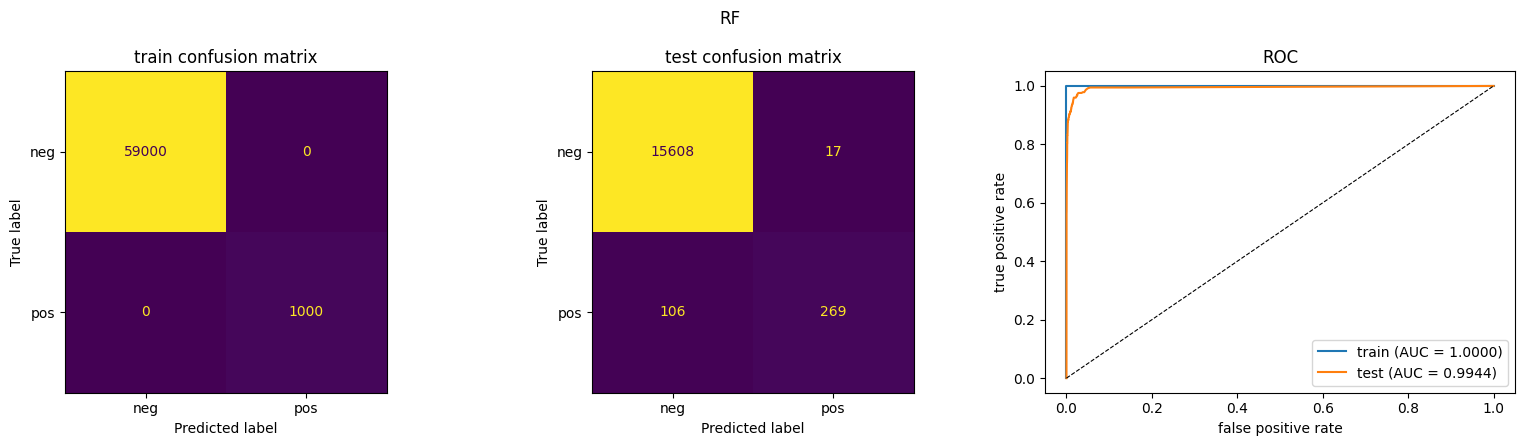

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
RF,0.0,1.0,0.007687,0.994446,106,17,0.717333,53170


In [11]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True,
                            n_jobs=-1, random_state=552).fit(X_train, y_train)
oob_error(rf)
evaluate(rf, 'RF')

Training error is 0 and AUC is 1.0. Test error is 0.77%, with AUC 0.9944, but 106 positives are missed (71.7% recall).

OOB error is 0.575% versus 0.769% test error. Their per-class errors are close: 0.12% / 27.5% for OOB and 0.11% / 28.3% for test (neg / pos). The higher positive fraction in the test set explains much of the gap. Using the training class ratio gives a test error of 0.578%, close to OOB.

## 1(d) Random forest with compensation for class imbalance

Common approaches are class weights, balanced sampling for each tree, over/undersampling, and a lower positive-class threshold. I try class weights and balanced RF (Chen, Liaw & Breiman, 2004). Weights make minority observations count more in splitting; balanced RF trains each tree using a downsampled majority class.

rows with OOB votes: 60000 | OOB error: 0.00767 (neg: 0.00102, pos: 0.4000)


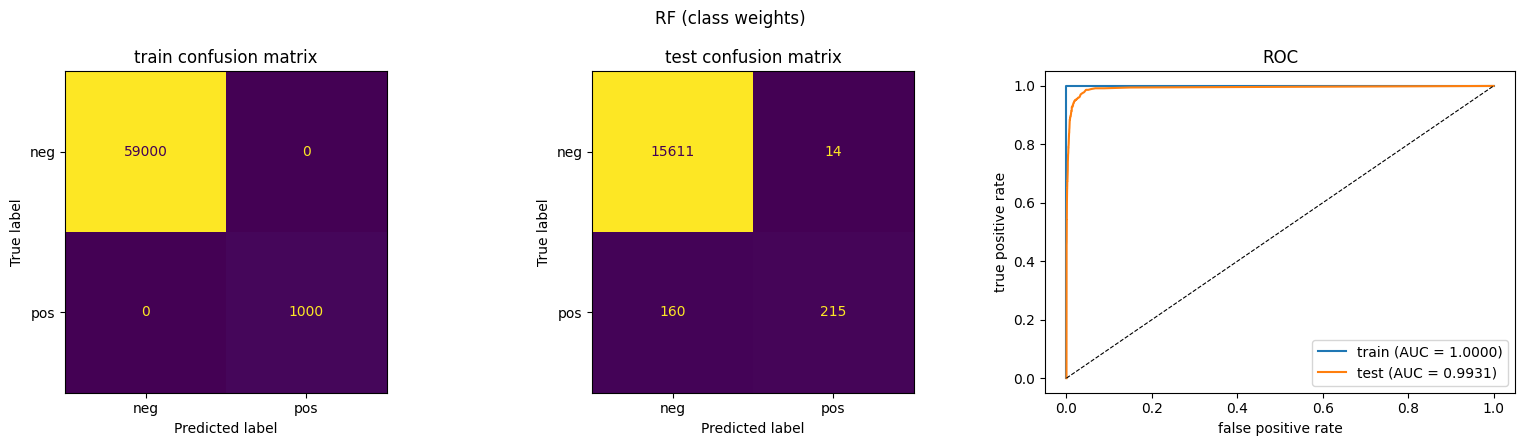

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
RF (class weights),0.0,1.0,0.010875,0.993082,160,14,0.573333,80140


In [12]:
# weighted RF: weights inversely proportional to the class counts in each bootstrap sample
rf_w = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', oob_score=True,
                              n_jobs=-1, random_state=552).fit(X_train, y_train)
oob_error(rf_w)
evaluate(rf_w, 'RF (class weights)')

rows with OOB votes: 51007 | OOB error: 0.05956 (neg: 0.06019, pos: 0.0280)


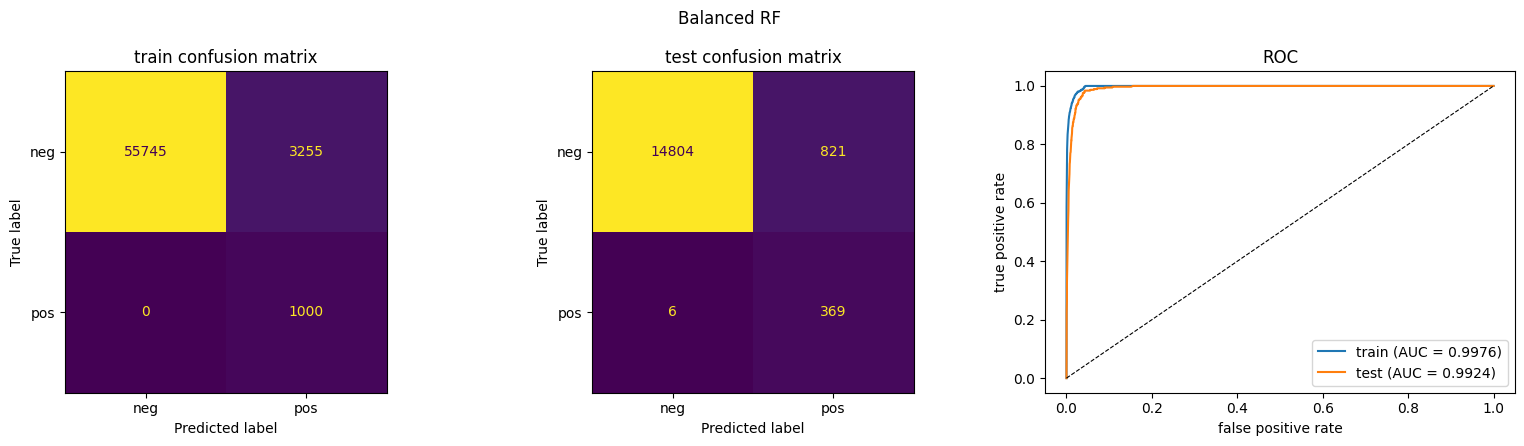

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
Balanced RF,0.05425,0.997593,0.051687,0.992404,6,821,0.984,11210


In [13]:
import warnings

# balanced RF: every tree is grown on a bootstrap of the 1000 pos + 1000 randomly drawn neg.
# Some negative rows get no OOB votes because of the undersampling. The default argmax would
# count these all-zero rows as correct negatives; oob_error() excludes rows without OOB votes.
with warnings.catch_warnings():
    warnings.filterwarnings(
        'ignore', message='Some inputs do not have OOB scores')
    brf = BalancedRandomForestClassifier(
        n_estimators=300, sampling_strategy='auto', replacement=False, bootstrap=True,
        oob_score=True, n_jobs=-1, random_state=552).fit(X_train, y_train)
oob_error(brf)
evaluate(brf, 'Balanced RF')

In [14]:
pd.DataFrame(results).T

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
RF,0.00000,1.000000,0.007687,0.994446,106.0,17.0,0.717333,53170.0
RF (class weights),0.00000,1.000000,0.010875,0.993082,160.0,14.0,0.573333,80140.0
Balanced RF,0.05425,0.997593,0.051687,0.992404,6.0,821.0,0.984000,11210.0


**Class weights** worsen test error to 1.09% and miss 160 positives. Weights affect splits and mixed leaves, but cannot change a pure leaf's prediction. OOB error is 0.77%; the per-class rates are close to the test rates.

**Balanced RF** misses only 6 positives (98.4% recall), but gives 821 false alarms. Test error rises to 5.17%, while cost falls from 53170 to 11210. Training error is 5.4% and test AUC is 0.9924.

Its OOB error is 5.96% on 51007 rows with votes. Each negative gets only about 2 OOB votes on average, so these predictions are less stable than test predictions from all 300 trees. Balancing improves recall and cost, not overall accuracy.

## 1(e) XGBoost with L1 penalty, no compensation

I use XGBoost as allowed in the question: `binary:logistic` minimizes logistic loss, and `reg_alpha` penalizes leaf weights with L1. Leaves contain constant scores, not separate logistic regressions. I select alpha by stratified 5-fold CV AUC, with median imputation inside each fold, and also report CV error.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
alphas = [0, 0.001, 0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
scoring = {'auc': 'roc_auc', 'accuracy': 'accuracy'}

def cv_table(search, param):
    r = search.cv_results_
    return pd.DataFrame({'alpha': r['param_' + param], 'cv_auc': r['mean_test_auc'],
                         'cv_error': 1 - r['mean_test_accuracy']})

# L1 regularization on the leaf weights, with imputation fitted inside each CV fold
xgb = XGBClassifier(objective='binary:logistic', n_estimators=300, learning_rate=0.05,
                    max_depth=3, random_state=552, n_jobs=-1)
xgb_pipe = Pipeline(
    [('impute', SimpleImputer(strategy='median')), ('xgb', xgb)])
xgb_cv = GridSearchCV(xgb_pipe, {'xgb__reg_alpha': alphas}, 
                      cv=skf, scoring=scoring, refit='auc').fit(X_train_raw, y_train)
print(cv_table(xgb_cv, 'xgb__reg_alpha'))
print('best alpha:', xgb_cv.best_params_['xgb__reg_alpha'],
      ' 5-fold CV error:', 1 - xgb_cv.cv_results_['mean_test_accuracy'][xgb_cv.best_index_])

     alpha    cv_auc  cv_error
0    0.000  0.989226  0.006433
1    0.001  0.989295  0.006517
2    0.010  0.989444  0.006350
3    0.100  0.989667  0.006433
4    0.500  0.989217  0.006450
5    1.000  0.988920  0.006433
6    5.000  0.989661  0.006717
7   10.000  0.989279  0.006933
8   50.000  0.985826  0.009317
9  100.000  0.983709  0.011200
best alpha: 0.1  5-fold CV error: 0.006433333333333402


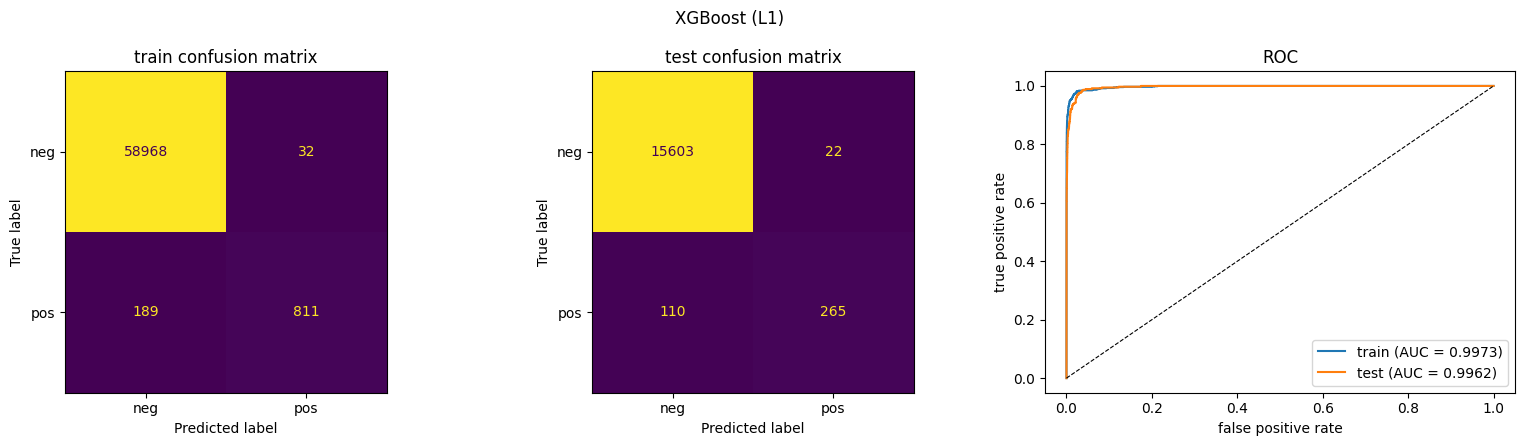

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
XGBoost (L1),0.003683,0.997314,0.00825,0.996249,110,22,0.706667,55220


In [16]:
evaluate(xgb_cv.best_estimator_, 'XGBoost (L1)')

The best alpha is 0.1 (CV AUC 0.9897); 50 and 100 reduce CV AUC. CV error is 0.64% versus 0.83% test error. Reweighting test errors to the training class ratio gives 0.63%, close to CV.

Training error is 0.37%, with AUC 0.9973; test AUC is 0.9962. Despite good ranking, the model misses 110 of 375 positives at the default threshold (70.7% recall).

## 1(f) XGBoost with L1 penalty + SMOTE

In [17]:
# right way: fit the imputer and SMOTE only on the 4 training folds.
# The validation fold keeps the real class ratio and contains no synthetic points.
smote_xgb = Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('smote', SMOTE(random_state=552)), ('xgb', xgb)])
smote_cv = GridSearchCV(smote_xgb, {'xgb__reg_alpha': alphas}, 
                        cv=skf, scoring=scoring, refit='auc').fit(X_train_raw, y_train)
print(cv_table(smote_cv, 'xgb__reg_alpha'))
best_alpha_s = smote_cv.best_params_['xgb__reg_alpha']
print('best alpha:', best_alpha_s,
      ' 5-fold CV error:', 1 - smote_cv.cv_results_['mean_test_accuracy'][smote_cv.best_index_])

     alpha    cv_auc  cv_error
0    0.000  0.986278  0.016317
1    0.001  0.986335  0.016267
2    0.010  0.986467  0.016133
3    0.100  0.986396  0.016167
4    0.500  0.986504  0.016350
5    1.000  0.986358  0.016233
6    5.000  0.986535  0.016400
7   10.000  0.986622  0.016850
8   50.000  0.986226  0.019067
9  100.000  0.985147  0.021600
best alpha: 10  5-fold CV error: 0.01685000000000003


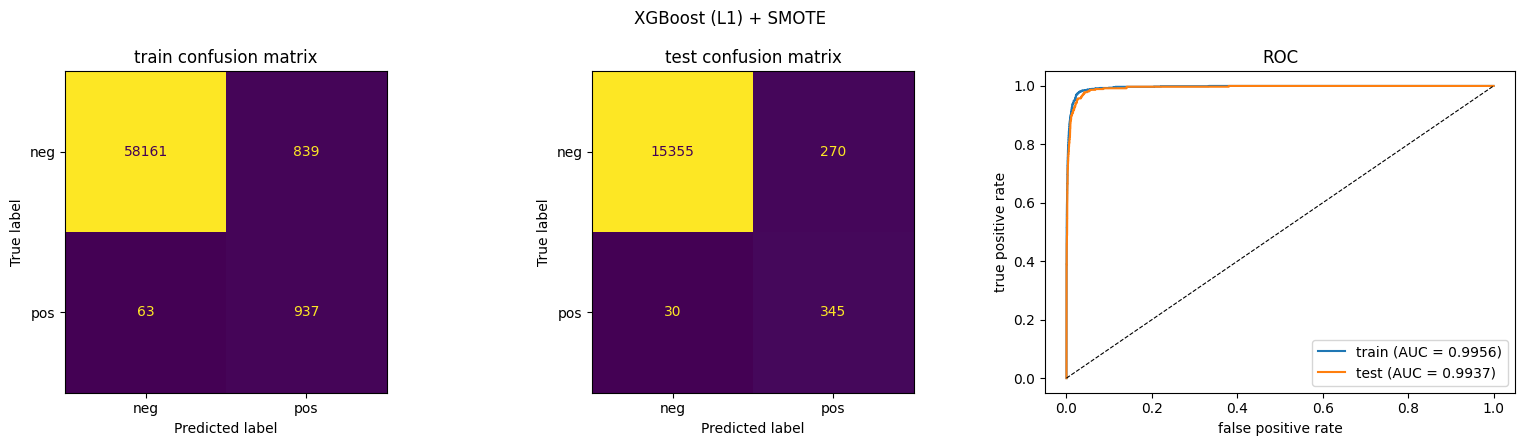

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
XGBoost (L1) + SMOTE,0.015033,0.995578,0.01875,0.993701,30,270,0.92,17700


In [18]:
# the refit model = SMOTE on the whole training set (59000 neg + 59000 pos) + XGBoost.
# Train metrics below are on the original 60000 training rows (predict does not resample).
evaluate(smote_cv.best_estimator_, 'XGBoost (L1) + SMOTE')

In [19]:
# wrong way, for comparison: SMOTE the whole training set first, then cross-validate on it
X_sm, y_sm = SMOTE(random_state=552).fit_resample(X_train, y_train)
print(X_sm.shape, y_sm.value_counts().to_dict())
xgb_best = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, reg_alpha=best_alpha_s,
                         random_state=552, n_jobs=-1)
wrong = cross_validate(xgb_best, X_sm, y_sm, cv=skf, scoring=scoring)
print('wrong-way CV error:', 1 - \
      wrong['test_accuracy'].mean(), ' CV AUC:', wrong['test_auc'].mean())

(118000, 170) {0: 59000, 1: 59000}


wrong-way CV error: 0.012161016949152503  CV AUC: 0.9990973987359955


In [20]:
pd.DataFrame(results).T

,train_error,train_auc,test_error,test_auc,test_FN,test_FP,test_recall,test_cost
RF,0.000000,1.000000,0.007687,0.994446,106.0,17.0,0.717333,53170.0
RF (class weights),0.000000,1.000000,0.010875,0.993082,160.0,14.0,0.573333,80140.0
Balanced RF,0.054250,0.997593,0.051687,0.992404,6.0,821.0,0.984000,11210.0
XGBoost (L1),0.003683,0.997314,0.008250,0.996249,110.0,22.0,0.706667,55220.0
XGBoost (L1) + SMOTE,0.015033,0.995578,0.018750,0.993701,30.0,270.0,0.920000,17700.0


With SMOTE, the best alpha is 10: CV error 1.69%, AUC 0.9866; test error 1.88%, AUC 0.9937.

**Right vs wrong CV:** the pipeline fits imputation and SMOTE on training folds only. Resampling before splitting leaks related synthetic points across folds, giving optimistic CV AUC 0.9991 and error 1.22%. That error also uses a different, 50/50 class ratio.

Compared with 1(e), SMOTE reduces FN from 110 to 30 (recall 70.7% to 92.0%), but increases FP from 22 to 270. Test error rises and AUC falls slightly; cost improves from 55220 to 17700. On the original training rows, error is 1.50% and AUC is 0.9956. Balanced RF has the lowest test cost, 11210.

## 2. ISLR 6.6.3

As the lasso constraint $\sum_j|\beta_j|\le s$ is relaxed:

| Part | Choice | Reason |
|---|---|---|
| (a) Training RSS | iv. Decreases | A larger feasible region cannot increase the minimum RSS. It eventually reaches the least-squares RSS. |
| (b) Test RSS | ii. U-shaped | Initially, reduced bias helps; later, fitting noise can increase test error. |
| (c) Variance | iii. Increases | More flexible coefficients depend more on the training sample. |
| (d) Squared bias | iv. Decreases | The model becomes less constrained. |
| (e) Irreducible error | v. Constant | Noise in $\epsilon$ does not depend on $s$. |

## 3. ISLR 6.6.5

Let $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$, $y_2=-y_1$, and $\hat\beta_0=0$.

**(a) Ridge:** the two squared residuals are equal, so the problem is

$$\min_{\beta_1,\beta_2}2[y_1-a(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b)** The RSS depends only on the sum of the coefficients. For a fixed sum, $\beta_1^2+\beta_2^2$ is smallest when they are equal. Thus, for $\lambda>0$, the unique solution is $\hat\beta_1=\hat\beta_2=2ay_1/(4a^2+\lambda)$.

**(c) Lasso:** replace the squared penalty by the absolute-value penalty:

$$\min_{\beta_1,\beta_2}2[y_1-a(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d)** Set $s=\beta_1+\beta_2$. Since $|\beta_1|+|\beta_2|\ge|s|$, equality holds for same-sign coefficients (including zero). For $a\ne0$, the optimal sum is

$$s^*=\operatorname{sign}(y_1/a)\max\left(|y_1/a|-\frac{\lambda}{4a^2},0\right).$$

If $s^*\ne0$, every same-sign pair summing to $s^*$ is optimal, e.g. $(s^*,0)$, $(0,s^*)$, and $(s^*/2,s^*/2)$. The solutions form a line segment. If $s^*=0$ or $a=0$, with $\lambda>0$, the solution is uniquely $(0,0)$.

## 4. ISLR 8.4.5

In [21]:
p_red = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print('trees voting Red:', (p_red > 0.5).sum(), 'of', len(p_red))
print('average P(Red | X):', p_red.mean())

trees voting Red: 6 of 10
average P(Red | X): 0.45


**Majority vote: Red**, since 6 of 10 trees vote Red. **Average probability: Green**, since $\bar p=4.5/10=0.45<0.5$. The four Green votes have more extreme probabilities, which pulls down the average.

## 5. ISLR 9.7.3

In [22]:
X9 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y9 = np.array(['Red'] * 4 + ['Blue'] * 3)

# check the hand solution with a linear SVC and a large C
mmc = SVC(kernel='linear', C=1e6).fit(X9, y9)
w, b = mmc.coef_[0], mmc.intercept_[0]
print('classes:', mmc.classes_, '(decision > 0 -> Red)')
print('w =', w.round(4), ' b =', b.round(4), ' -> divided by', w[1].round(4),
      ':', (b / w[1]).round(4), (w / w[1]).round(4))
print('support vectors (obs #):', sorted((mmc.support_ + 1).tolist()))
print('margin M = 1/||w|| =', (1 / np.linalg.norm(w)).round(4))

classes: ['Blue' 'Red'] (decision > 0 -> Red)
w = [-1.9994  1.9994]  b = 0.9997  -> divided by 1.9994 : 0.5 [-1.  1.]
support vectors (obs #): [2, 3, 5, 6]
margin M = 1/||w|| = 0.3537


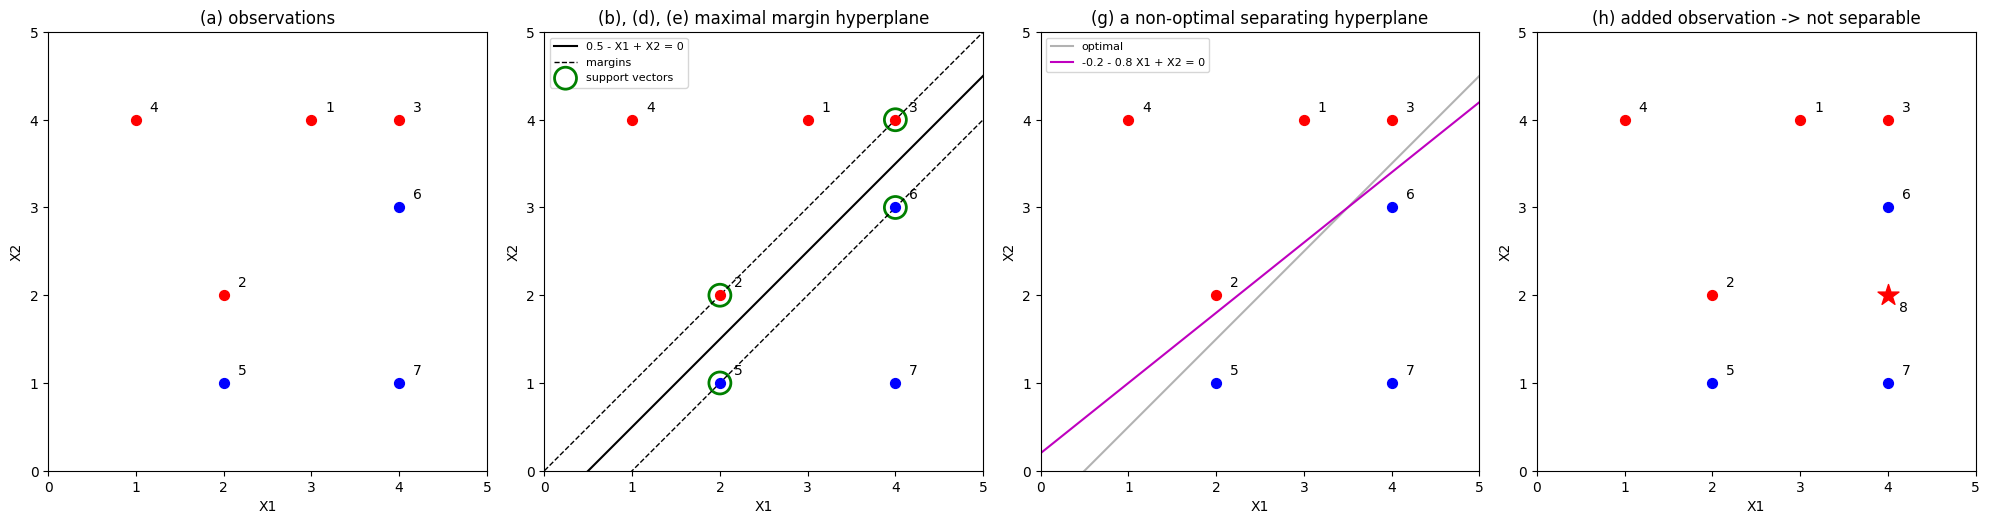

In [23]:
x1 = np.linspace(0, 5, 2)

def base(a, title):
    for c in ['Red', 'Blue']:
        a.scatter(*X9[y9 == c].T, c=c.lower(), s=50, zorder=3)
    for i, (u, v) in enumerate(X9):
        a.annotate(str(i + 1), (u, v),
                   textcoords='offset points', xytext=(10, 6))
    a.set(xlim=(0, 5), ylim=(0, 5), xlabel='X1',
          ylabel='X2', title=title, aspect='equal')

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
base(ax[0], '(a) observations')

base(ax[1], '(b), (d), (e) maximal margin hyperplane')
ax[1].plot(x1, x1 - 0.5, 'k-', label='0.5 - X1 + X2 = 0')
ax[1].plot(x1, x1 - 1, 'k--', lw=1, label='margins')
ax[1].plot(x1, x1, 'k--', lw=1)
ax[1].scatter(*X9[[1, 2, 4, 5]].T, s=250, facecolors='none', edgecolors='green',
              lw=2, label='support vectors')
ax[1].legend(loc='upper left', fontsize=8)

base(ax[2], '(g) a non-optimal separating hyperplane')
ax[2].plot(x1, x1 - 0.5, 'k-', alpha=0.3, label='optimal')
ax[2].plot(x1, 0.8 * x1 + 0.2, 'm-', label='-0.2 - 0.8 X1 + X2 = 0')
ax[2].legend(loc='upper left', fontsize=8)

base(ax[3], '(h) added observation -> not separable')
ax[3].scatter(4, 2, c='red', marker='*', s=250, zorder=3)
ax[3].annotate('8', (4, 2), textcoords='offset points', xytext=(8, -12))
plt.tight_layout()
plt.show()

**(a)** The first plot shows the observations.

**(b)** The closest class boundaries are $X_2=X_1$ and $X_2=X_1-1$, so the optimal hyperplane lies halfway between them: $0.5-X_1+X_2=0$.

**(c)** Predict Red if $0.5-X_1+X_2>0$, otherwise Blue. Thus $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$.

**(d)** The dashed lines are the margins. The distance from the hyperplane to either is $M=0.5/\sqrt2\approx0.354$.

**(e)** Support vectors: observations 2, 3, 5, and 6, circled in green.

**(f)** Observation 7 is about 1.77 from the hyperplane, outside the margin. A small movement that keeps it outside does not change the solution.

**(g)** The third plot uses $-0.2-0.8X_1+X_2=0$. It separates the classes, but its margin is only $0.2/\sqrt{1+0.8^2}\approx0.156$.

**(h)** Add a Red point at $(4,2)$, the midpoint of Blue observations 6 and 7. Any half-plane containing both Blue endpoints contains this midpoint, so linear separation is impossible.

## 6. AI Usage

The following questions summarize the topics I discussed with Codex:

“Should I fit the imputer and apply SMOTE before cross-validation, or only on the training data inside each fold? How can I use imblearn’s Pipeline to avoid data leakage?”

“Balanced random forest gives a warning that some rows do not have OOB predictions. How should I calculate the OOB error for these results and compare it with the test error?”

“After balancing the classes, the model misses fewer positive cases but has a higher misclassification rate. How should I explain this trade-off using recall, AUC, and the costs of false positives and false negatives?”